# Ground temperature beneath snow, through melt, and after disappearance
PPSA · TRAM · HEEN — six existing soil-enabled lapse-rate runs. These are modeled responses of **idealized soil**, not site-validated ground temperatures. SNOWPACK resolves heat conduction, phase change and water movement in a layered snow–soil column. Snow insulates that column; loss of snow exposes it to atmospheric and radiative forcing.

All analysis dates use the project's UTC convention. The reference is actually located at `sites/all_sites/5_read_snowpack_output_compare_all_sites_lapserate_soil_figure.ipynb`. No simulations are rerun. Outputs go to `figures/soil_temperature/`.


In [1]:
from pathlib import Path
from io import StringIO
import os, json, hashlib, configparser, re
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display, Markdown
plt.rcParams.update({'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False, 'figure.dpi':110})
ROOT = Path.cwd()
while not (ROOT/'sites').is_dir():
    if ROOT.parent == ROOT: raise RuntimeError('Run from inside snow_modeling_point')
    ROOT=ROOT.parent
MODEL=Path(os.environ.get('SNOWPACK_SITES','/home/cassie/python/models/run_snowpack/sites'))
OUT=ROOT/'figures'/'soil_temperature'; OUT.mkdir(parents=True,exist_ok=True)
REF=ROOT/'sites/all_sites/5_read_snowpack_output_compare_all_sites_lapserate_soil_figure.ipynb'
ref=json.loads(REF.read_text()); source='\n\n'.join(''.join(c['source']) for c in ref['cells'])
# Reuse the established site labels, paths, styling and melt-out algorithm verbatim.
settings=next(''.join(c['source']) for c in ref['cells'] if c['cell_type']=='code' and 'SITE_CONFIG =' in ''.join(c['source']))
exec(settings[settings.index('SITE_CONFIG ='):])
start=source.index('def melt_out('); end=source.index('\nmetric_rows =',start)
exec(source[start:end])
DEPTHS=[5,10,20,50]
GRID=np.arange(2,101,dtype=float) # cm perpendicular to local slope
TARGETS=np.r_[DEPTHS,GRID]
def save(fig,stem):
    for ext in ['png','pdf']: fig.savefig(OUT/f'{stem}.{ext}',dpi=200,bbox_inches='tight')
def export(df,name): df.to_csv(OUT/f'{name}.csv',index=False)
def smet(path):
    h={}
    with Path(path).open() as f:
        for line in f:
            if line.strip()=='[DATA]':break
            if '=' in line and not line.lstrip().startswith('#'):
                k,v=line.split('=',1);h[k.strip()]=v.strip()
        d=pd.read_csv(f,sep=r'\s+',names=h['fields'].split())
    return h,d
hourly={}; daily={}; profiles={}; inventory=[]; provenance=[]; initial={}; obs={}; obs_audit=[]


## Definitions and depth extraction
`TSG` is the **node** at the ground surface (snow–soil contact when snow is present); `TSS_mod` is the top of snow when snow-covered. `T_bottom` is **node 0 at the bottom of the entire soil column**, not the snow base and not a shallow soil sensor. Raw SMET temperature values are °C; metadata transforms them to K, after which this notebook converts to °C. `Qg` is the lower-boundary geothermal flux; `Qg0` is the time-varying snow–soil interface flux, positive upward (negative means heat entering soil). The writer and flux calculation verify these distinctions.

PRO code 0501 supplies **vertical node coordinates in cm**, zero at ground, negative below. With the retained 38° slope the 5 m model column appears 6.345 m deep vertically. We multiply coordinates by cos(slope) to report **slope-normal burial depths**: 5, 10, 20, 50 cm (vertical equivalents approximately 6.35, 12.69, 25.38, 63.45 cm). PRO 0503 is element temperature (°C), 0506 liquid volume (%) and 0515 ice volume (%). Element values are assigned to the midpoint of their bounding nodes, then linearly interpolated between the two adjacent soil midpoints. No snow elements, extrapolation, time interpolation, or bridging missing adjacent values is allowed. These are reconstructed layer-scale temperatures, not native nodal sensor values. Heatmaps begin at 2 cm to avoid extrapolating beyond the shallowest element midpoint (~1 cm).

Sources: installed SNOWPACK 3.7 documentation (`/home/cassie/programs/snowpack/usr/share/doc/snowpack/html/`), [SMET specification](https://snowpack.slf.ch/doc-release/html/smet.html), [official SmetIO writer](https://git.wsl.ch/snow-models/snowpack/-/blob/master/snowpack/plugins/SmetIO.cc), [AsciiIO profile writer](https://git.wsl.ch/snow-models/snowpack/-/blob/master/snowpack/plugins/AsciiIO.cc), and [flux implementation](https://git.wsl.ch/snow-models/snowpack/-/blob/master/snowpack/DataClasses.cc). Source snapshots used for verification are saved beside outputs; master is supporting evidence rather than proof of an exact executable build match.


In [2]:
# Stream large PRO files: retain only soil fields; validate every record's array sizes.
def read_pro(path,cosine,nsoil):
    times=[]; values={k:[] for k in ['T','water','ice']}; record={}; t=None
    def flush():
        if t is None:return
        z=record['0501']; assert len(z)==len(record['0503'])+1
        assert np.all(z[:nsoil]<0) and abs(z[nsoil])<.02
        depth=-(z[:nsoil]+z[1:nsoil+1])/2*cosine
        order=np.argsort(depth); x=depth[order]
        assert np.all(np.diff(x)>0)
        times.append(t)
        for label,key in [('T','0503'),('water','0506'),('ice','0515')]:
            y=record[key][:nsoil][order]
            # np.interp propagates missing adjacent values, with no extrapolation.
            values[label].append(np.interp(TARGETS,x,y,left=np.nan,right=np.nan))
    with path.open() as f:
        for line in f:
            if line.strip()=='[DATA]':break
        for line in f:
            if line.startswith('0500,'):
                flush();t=pd.to_datetime(line[5:].strip(),format='%d.%m.%Y %H:%M:%S');record={}
            elif t is not None and line[:4] in ['0501','0503','0506','0515']:
                pieces=line.rstrip().split(',');a=np.asarray(pieces[2:],dtype=float)
                assert len(a)==int(pieces[1]); a[a<=-999]=np.nan;record[pieces[0]]=a
        flush()
    idx=pd.DatetimeIndex(times,name='time');assert idx.is_unique and idx.is_monotonic_increasing
    return {k:pd.DataFrame(v,index=idx,columns=range(len(TARGETS))) for k,v in values.items()}

for site,cfg in SITE_CONFIG.items():
    for forcing,prefix in FORCINGS.items():
        stem=f'{prefix}_{site}_{cfg[forcing]}_soil';base=MODEL/site
        paths={ext:base/'output'/f'{stem}.{ext}' for ext in ['ini','smet','pro']}
        cp=configparser.ConfigParser(interpolation=None, delimiters=("=",));cp.read(paths['ini'])
        sno=(base/'config'/cp['INPUT']['SNOWPATH']/cp['INPUT']['SNOWFILE1']).resolve()
        sh,sd=smet(sno);nsoil=int(sh['nSoilLayerData']);initial[site,forcing]=sd.copy()
        h,d=smet(paths['smet']);fields=h['fields'].split();mult=np.array(h['units_multiplier'].split(),float);off=np.array(h['units_offset'].split(),float)
        d.index=pd.DatetimeIndex(pd.to_datetime(d.pop('timestamp')),name='time');assert d.index.is_unique and d.index.is_monotonic_increasing
        d=d.replace(float(h['nodata']),np.nan)
        for j,k in enumerate(fields[1:],1):
            d[k]=d[k]*mult[j]+off[j]
            if h['plot_unit'].split()[j]=='K':d[k]-=273.15
        d['HS_cm']=d.HS_mod*100
        cosine=np.cos(np.deg2rad(float(sh['SlopeAngle'])))
        p=read_pro(paths['pro'],cosine,nsoil);profiles[site,forcing]=p
        for i,z in enumerate(DEPTHS):
            for name in p:d[f'{name}_{z}']=p[name][i].reindex(d.index)
        hourly[site,forcing]=d
        means=d.resample('D').mean();counts=d.resample('D').count();means=means.where(counts>=18)
        means['HS_max_cm']=d.HS_cm.resample('D').max().where(counts.HS_cm>=18)
        daily[site,forcing]=means
        span=d.index.to_series().diff();profile_span=p['T'].index.to_series().diff()
        inventory.append(dict(site=site,forcing=forcing,start=d.index.min(),end=d.index.max(),soil_depth_m=sd.Layer_Thick.sum(),vertical_depth_m=sd.Layer_Thick.sum()/cosine,layers=nsoil,
            layering_surface_down='5×.02,4×.05,7×.10,8×.25,4×.50 m',material='idealized mineral LOAM; rg='+str(sd.rg.iloc[0])+' mm',
            initial_C_min=sd["T"].min()-273.15,initial_C_max=sd["T"].max()-273.15,initial_liquid=sd.Vol_Frac_W.iloc[0],initial_ice=sd.Vol_Frac_I.iloc[0],initial_solid=sd.Vol_Frac_S.iloc[0],
            mineral_density=sd.Rho_S.iloc[0],input_conductivity=sd.Conduc_S.iloc[0],input_heat_capacity=sd.HeatCapac_S.iloc[0],lower_thermal='GEO_HEAT='+cp['SNOWPACK']['GEO_HEAT']+' W/m² upward; flux BC',
            soil_flux=cp['SNOWPACK']['SOIL_FLUX'],advanced_soil_flux=cp['SNOWPACKADVANCED'].get('SOIL_FLUX','unset'),water_model=cp['SNOWPACKADVANCED']['WATERTRANSPORTMODEL_SOIL'],conductivity=cp['SNOWPACKADVANCED']['SOIL_THERMAL_CONDUCTIVITY'],
            spinup='none added; README_soil.md',smet_gaps=int((span.iloc[1:]!=pd.Timedelta(hours=1)).sum()),pro_gaps=int((profile_span.iloc[1:]!=pd.Timedelta(hours=1)).sum()),
            diagnostics='TSG,T_bottom,Qg,Qg0,water/ice mass,snow runoff; hourly PRO T/liquid/ice',ini=str(paths['ini']),sno=str(sno)))
        for path in [paths['ini'],sno,base/'README_soil.md']:
            provenance.append(dict(path=str(path),size=path.stat().st_size,sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
        for path in [paths['smet'],paths['pro']]:provenance.append(dict(path=str(path),size=path.stat().st_size,mtime_ns=path.stat().st_mtime_ns))
        print(site,forcing,len(d),'hourly records; extracted',len(p['T']),'profiles')
inventory=pd.DataFrame(inventory);export(inventory,'run_inventory');export(pd.DataFrame(provenance),'source_manifest')
display(inventory[['site','forcing','start','end','soil_depth_m','layers','material','initial_C_min','initial_liquid','initial_ice','lower_thermal','diagnostics']].round(3))
pair_initial=[]
for site in SITE_CONFIG:
    a=initial[site,'hrrr'].drop(columns='timestamp'); b=initial[site,'mixed'].drop(columns='timestamp')
    pair_initial.append(dict(site=site,identical_layer_state=a.equals(b),same_start=inventory.query('site==@site').start.nunique()==1))
display(pd.DataFrame(pair_initial));export(pd.DataFrame(pair_initial),'initialization_pairs')
# Preserve configuration and small documentation snapshots without copying large simulations.
for row in provenance:
    path=Path(row['path'])
    if 'sha256' in row:
        dest=OUT/'provenance'/path.relative_to(MODEL);dest.parent.mkdir(parents=True,exist_ok=True);dest.write_bytes(path.read_bytes())


ppsa hrrr 51883 hourly records; extracted 51883 profiles


ppsa mixed 51883 hourly records; extracted 51883 profiles


tram hrrr 51883 hourly records; extracted 51883 profiles


tram mixed 25579 hourly records; extracted 25579 profiles


heen hrrr 51883 hourly records; extracted 51883 profiles


heen mixed 26280 hourly records; extracted 26280 profiles


/tmp/ipykernel_3646204/4002158761.py:64: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(inventory[['site','forcing','start','end','soil_depth_m','layers','material','initial_C_min','initial_liquid','initial_ice','lower_thermal','diagnostics']].round(3))


,site,forcing,start,end,soil_depth_m,layers,material,initial_C_min,initial_liquid,initial_ice,lower_thermal,diagnostics
0,ppsa,hrrr,2019-10-01 06:00:00,2025-09-01 00:00:00,5.0,28,idealized mineral LOAM; rg=2.5 mm,2.044,0.25,0.0,GEO_HEAT=0.06 W/m² upward; flux BC,"TSG,T_bottom,Qg,Qg0,water/ice mass,snow runoff..."
1,ppsa,mixed,2019-10-01 06:00:00,2025-09-01 00:00:00,5.0,28,idealized mineral LOAM; rg=2.5 mm,2.044,0.25,0.0,GEO_HEAT=0.06 W/m² upward; flux BC,"TSG,T_bottom,Qg,Qg0,water/ice mass,snow runoff..."
2,tram,hrrr,2019-10-01 06:00:00,2025-09-01 00:00:00,5.0,28,idealized mineral LOAM; rg=2.5 mm,2.747,0.25,0.0,GEO_HEAT=0.06 W/m² upward; flux BC,"TSG,T_bottom,Qg,Qg0,water/ice mass,snow runoff..."
3,tram,mixed,2022-10-01 06:00:00,2025-09-01 00:00:00,5.0,28,idealized mineral LOAM; rg=2.5 mm,2.747,0.25,0.0,GEO_HEAT=0.06 W/m² upward; flux BC,"TSG,T_bottom,Qg,Qg0,water/ice mass,snow runoff..."
4,heen,hrrr,2019-10-01 06:00:00,2025-09-01 00:00:00,5.0,28,idealized mineral LOAM; rg=2.5 mm,2.947,0.25,0.0,GEO_HEAT=0.06 W/m² upward; flux BC,"TSG,T_bottom,Qg,Qg0,water/ice mass,snow runoff..."
5,heen,mixed,2019-10-01 06:00:00,2022-09-30 05:00:00,5.0,28,idealized mineral LOAM; rg=2.5 mm,2.947,0.25,0.0,GEO_HEAT=0.06 W/m² upward; flux BC,"TSG,T_bottom,Qg,Qg0,water/ice mass,snow runoff..."


,site,identical_layer_state,same_start
0,ppsa,True,True
1,tram,True,False
2,heen,True,True


Nominal initial water/ice/air/solid fractions are 0.25/0/0.149/0.601. The Richards hydraulic-class mapping adjusts mineral volume (~0.565), and `REQ_INITIALIZE_SOIL` redistributes water hydrostatically: the input water fraction is not the first output profile. The soil conductivity uses Cosenza2003; `Conduc_S` is a mineral input, not constant bulk conductivity. The two forcings have the same assumed layer state per site, but TRAM has different start dates and hence different histories by a common later spring. First simulated years are flagged, not treated as spin-up. Excluding one year does not demonstrate equilibration of a 5 m column.

## Coverage, snow disappearance and seasonal metrics
Daily values require **18 distinct valid hourly samples** (model outputs are hourly). Gaps remain missing. Melt-out uses the reference algorithm verbatim: first confirmed snow-free day after the last snow-covered day from the seasonal peak through August 31; seven consecutive valid days with daily maximum HS ≤1 cm and SWE ≤1 kg m⁻², ≥10 cm seasonal peak and ≥90% March–August valid days. Observed dates use HS only.

Winter = December 1–February end; require ≥90% valid daily values. Standard deviation is between daily means, not hourly variability. Pre/post windows are days −14…−1 and +1…+14, excluding melt day; require **all 14 valid days** for each mean. Warming search = March 1–August 31: first of three consecutive calendar days >+0.5°C, with the immediately preceding valid day ≤+0.5°C needed to confirm an observed crossing. Already warm at the start or a run beginning after a gap is censored. Negative lags are retained. This is a **warming threshold**, not proof of thaw. Missing melt dates, incomplete windows and first years remain explicit in the tidy table.


In [3]:
for site,cfg in SITE_CONFIG.items():
    with xr.open_dataset(cfg['obs']) as ds:
        s=ds.hs.to_series();unit=str(ds.hs.attrs.get('units','')).lower()
        obs_audit.append(dict(site=site,path=cfg['obs'],variables=';'.join(ds.data_vars),soil_variables=';'.join(v for v in ds if any(t in v.lower() for t in ['soil','ground','ts_']))))
    if unit=='m':s=s*100
    else:assert unit=='cm'
    s.index=pd.DatetimeIndex(pd.to_datetime(s.index,utc=True)).tz_convert(None)
    s=s.groupby(level=0).mean().sort_index();obs[site]=s.where(s>=0)
export(pd.DataFrame(obs_audit),'observation_audit');display(pd.DataFrame(obs_audit))
def window(s,idx,required):
    a=s.reindex(idx); count=a.notna().sum()
    return (a.mean() if count>=required else np.nan),int(count)
def crossing(s,wy):
    idx=pd.date_range(f'{wy}-03-01',f'{wy}-08-31');a=s.reindex(idx)
    if pd.notna(a.iloc[0]) and a.iloc[0]>.5:return pd.NaT,'already_above_at_start'
    good=(a>.5)&a.notna();ends=good.rolling(3,min_periods=3).sum()
    for end in ends[ends==3].index:
        first=end-pd.Timedelta(days=2);prev=a.get(first-pd.Timedelta(days=1),np.nan)
        if pd.isna(prev):return pd.NaT,'crossing_censored_by_gap'
        if prev<=.5:return first,'observed_crossing'
    return pd.NaT,'no_confirmed_crossing'
rows=[]
for (site,forcing),d in hourly.items():
    years=d.index.year+(d.index.month>=10);first=int(years.min());day=daily[site,forcing]
    for wy,season in d.groupby(years):
        melt,status=melt_out(season.HS_cm,season.SWE)
        observed,ostatus=melt_out(obs[site].reindex(season.index))
        winter=pd.date_range(f'{wy-1}-12-01',pd.Timestamp(wy,3,1)-pd.Timedelta(days=1))
        for depth in DEPTHS:
            s=day[f'T_{depth}'];wm,wcount=window(s,winter,int(np.ceil(.9*len(winter))))
            warm,wstatus=crossing(s,wy)
            pre=post=np.nan;ncpre=ncpost=0;tm=np.nan
            if pd.notna(melt):
                pre,ncpre=window(s,pd.date_range(melt-pd.Timedelta(days=14),periods=14),14)
                post,ncpost=window(s,pd.date_range(melt+pd.Timedelta(days=1),periods=14),14);tm=s.get(melt,np.nan)
            under=day.loc[f'{wy-1}-10-01':f'{wy}-08-31'];under=under.loc[under.HS_max_cm>1,f'T_{depth}']
            rows.append(dict(site=site,forcing=forcing,water_year=int(wy),depth_cm=depth,first_simulated_season=int(wy)==first,
                warming_HS_mean_cm=day.HS_cm.get(warm,np.nan),warming_HS_max_cm=day.HS_max_cm.get(warm,np.nan),
                partial_water_year=season.index.min()>pd.Timestamp(wy-1,10,1) or season.index.max()<pd.Timestamp(wy,9,30,23),
                winter_mean_C=wm,winter_sd_C=s.reindex(winter).std() if np.isfinite(wm) else np.nan,winter_valid_days=wcount,winter_expected_days=len(winter),
                under_snow_mean_C=under.mean(),under_snow_valid_days=under.notna().sum(),melt_date=melt,melt_status=status,observed_melt=observed,observed_melt_status=ostatus,
                T_melt_C=tm,pre14_C=pre,post14_C=post,post_minus_pre_C=post-pre,post_minus_melt_C=post-tm,pre_valid_days=ncpre,post_valid_days=ncpost,
                incomplete_14d_window=ncpre<14 or ncpost<14,warming_date=warm,warming_status=wstatus,warming_lag_days=(warm-melt).days if pd.notna(warm) and pd.notna(melt) else np.nan))
metrics=pd.DataFrame(rows)
ref5=metrics.query('depth_cm==5')[['site','forcing','water_year','warming_date']].rename(columns={'warming_date':'warming_5cm'})
metrics=metrics.merge(ref5,on=['site','forcing','water_year'],validate='many_to_one')
metrics['warming_lag_vs_5cm_days']=(metrics.warming_date-metrics.warming_5cm).dt.days
export(metrics,'season_depth_metrics');display(metrics.round(2))
print('Warming status counts:');display(metrics.groupby(['site','forcing','warming_status']).size().rename('rows').to_frame())


,site,path,variables,soil_variables
0,ppsa,/hdd/snow_hydrology/met_station/ppsa2/pppsa_me...,temp;rh;hs;precip_accum;precip_rate;precip_acc...,
1,tram,/hdd/snow_hydrology/met_station/tram/tram_met_...,temp;rh;hs;solar_rad;precip_accum;precip_accum...,
2,heen,/hdd/snow_hydrology/met_station/snotel/heenlat...,swe;temp;hs;rh;precip_accum;wind;wind_dir;pres...,


/tmp/ipykernel_3646204/3330184421.py:48: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  export(metrics,'season_depth_metrics');display(metrics.round(2))


,site,forcing,water_year,depth_cm,first_simulated_season,warming_HS_mean_cm,warming_HS_max_cm,partial_water_year,winter_mean_C,winter_sd_C,...,post_minus_pre_C,post_minus_melt_C,pre_valid_days,post_valid_days,incomplete_14d_window,warming_date,warming_status,warming_lag_days,warming_5cm,warming_lag_vs_5cm_days
0,ppsa,hrrr,2020,5,True,18.41,20.55,True,0.15,0.08,...,9.39,4.44,14,14,False,2020-06-22,observed_crossing,-4.0,2020-06-22,0.0
1,ppsa,hrrr,2020,10,True,18.41,20.55,True,0.21,0.11,...,8.94,4.44,14,14,False,2020-06-22,observed_crossing,-4.0,2020-06-22,0.0
2,ppsa,hrrr,2020,20,True,13.14,15.85,True,0.33,0.16,...,8.00,4.21,14,14,False,2020-06-23,observed_crossing,-3.0,2020-06-22,1.0
3,ppsa,hrrr,2020,50,True,6.66,9.69,True,0.68,0.30,...,5.25,3.60,14,14,False,2020-06-24,observed_crossing,-2.0,2020-06-22,2.0
4,ppsa,hrrr,2021,5,False,17.49,21.26,False,0.02,0.02,...,8.31,-1.71,14,14,False,2021-07-02,observed_crossing,-3.0,2021-07-02,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,heen,mixed,2021,50,False,2.27,6.62,False,0.61,0.11,...,5.61,4.57,14,14,False,2021-06-21,observed_crossing,-1.0,2021-06-20,1.0
116,heen,mixed,2022,5,False,13.06,16.43,True,-0.01,0.03,...,10.48,5.42,14,14,False,2022-06-17,observed_crossing,-3.0,2022-06-17,0.0
117,heen,mixed,2022,10,False,13.06,16.43,True,0.02,0.01,...,9.77,5.12,14,14,False,2022-06-17,observed_crossing,-3.0,2022-06-17,0.0
118,heen,mixed,2022,20,False,8.28,10.56,True,0.18,0.03,...,8.37,4.79,14,14,False,2022-06-18,observed_crossing,-2.0,2022-06-17,1.0


Warming status counts:


rows
site forcing warming_status              
heen hrrr    already_above_at_start     4
             observed_crossing         20
     mixed   observed_crossing         12
ppsa hrrr    already_above_at_start     3
             observed_crossing         21
     mixed   already_above_at_start     3
             observed_crossing         21
tram hrrr    already_above_at_start     4
             observed_crossing         20
     mixed   already_above_at_start     2
             observed_crossing         10

## Seasonal overview
Separate forcing columns preserve the depth response. Temperature and snow depth share dates in each site/forcing pair. Black snow curves are observations; dashed vertical lines mark modeled disappearance and dotted gray lines observed disappearance. All available model years are shown, with different record lengths explicit.


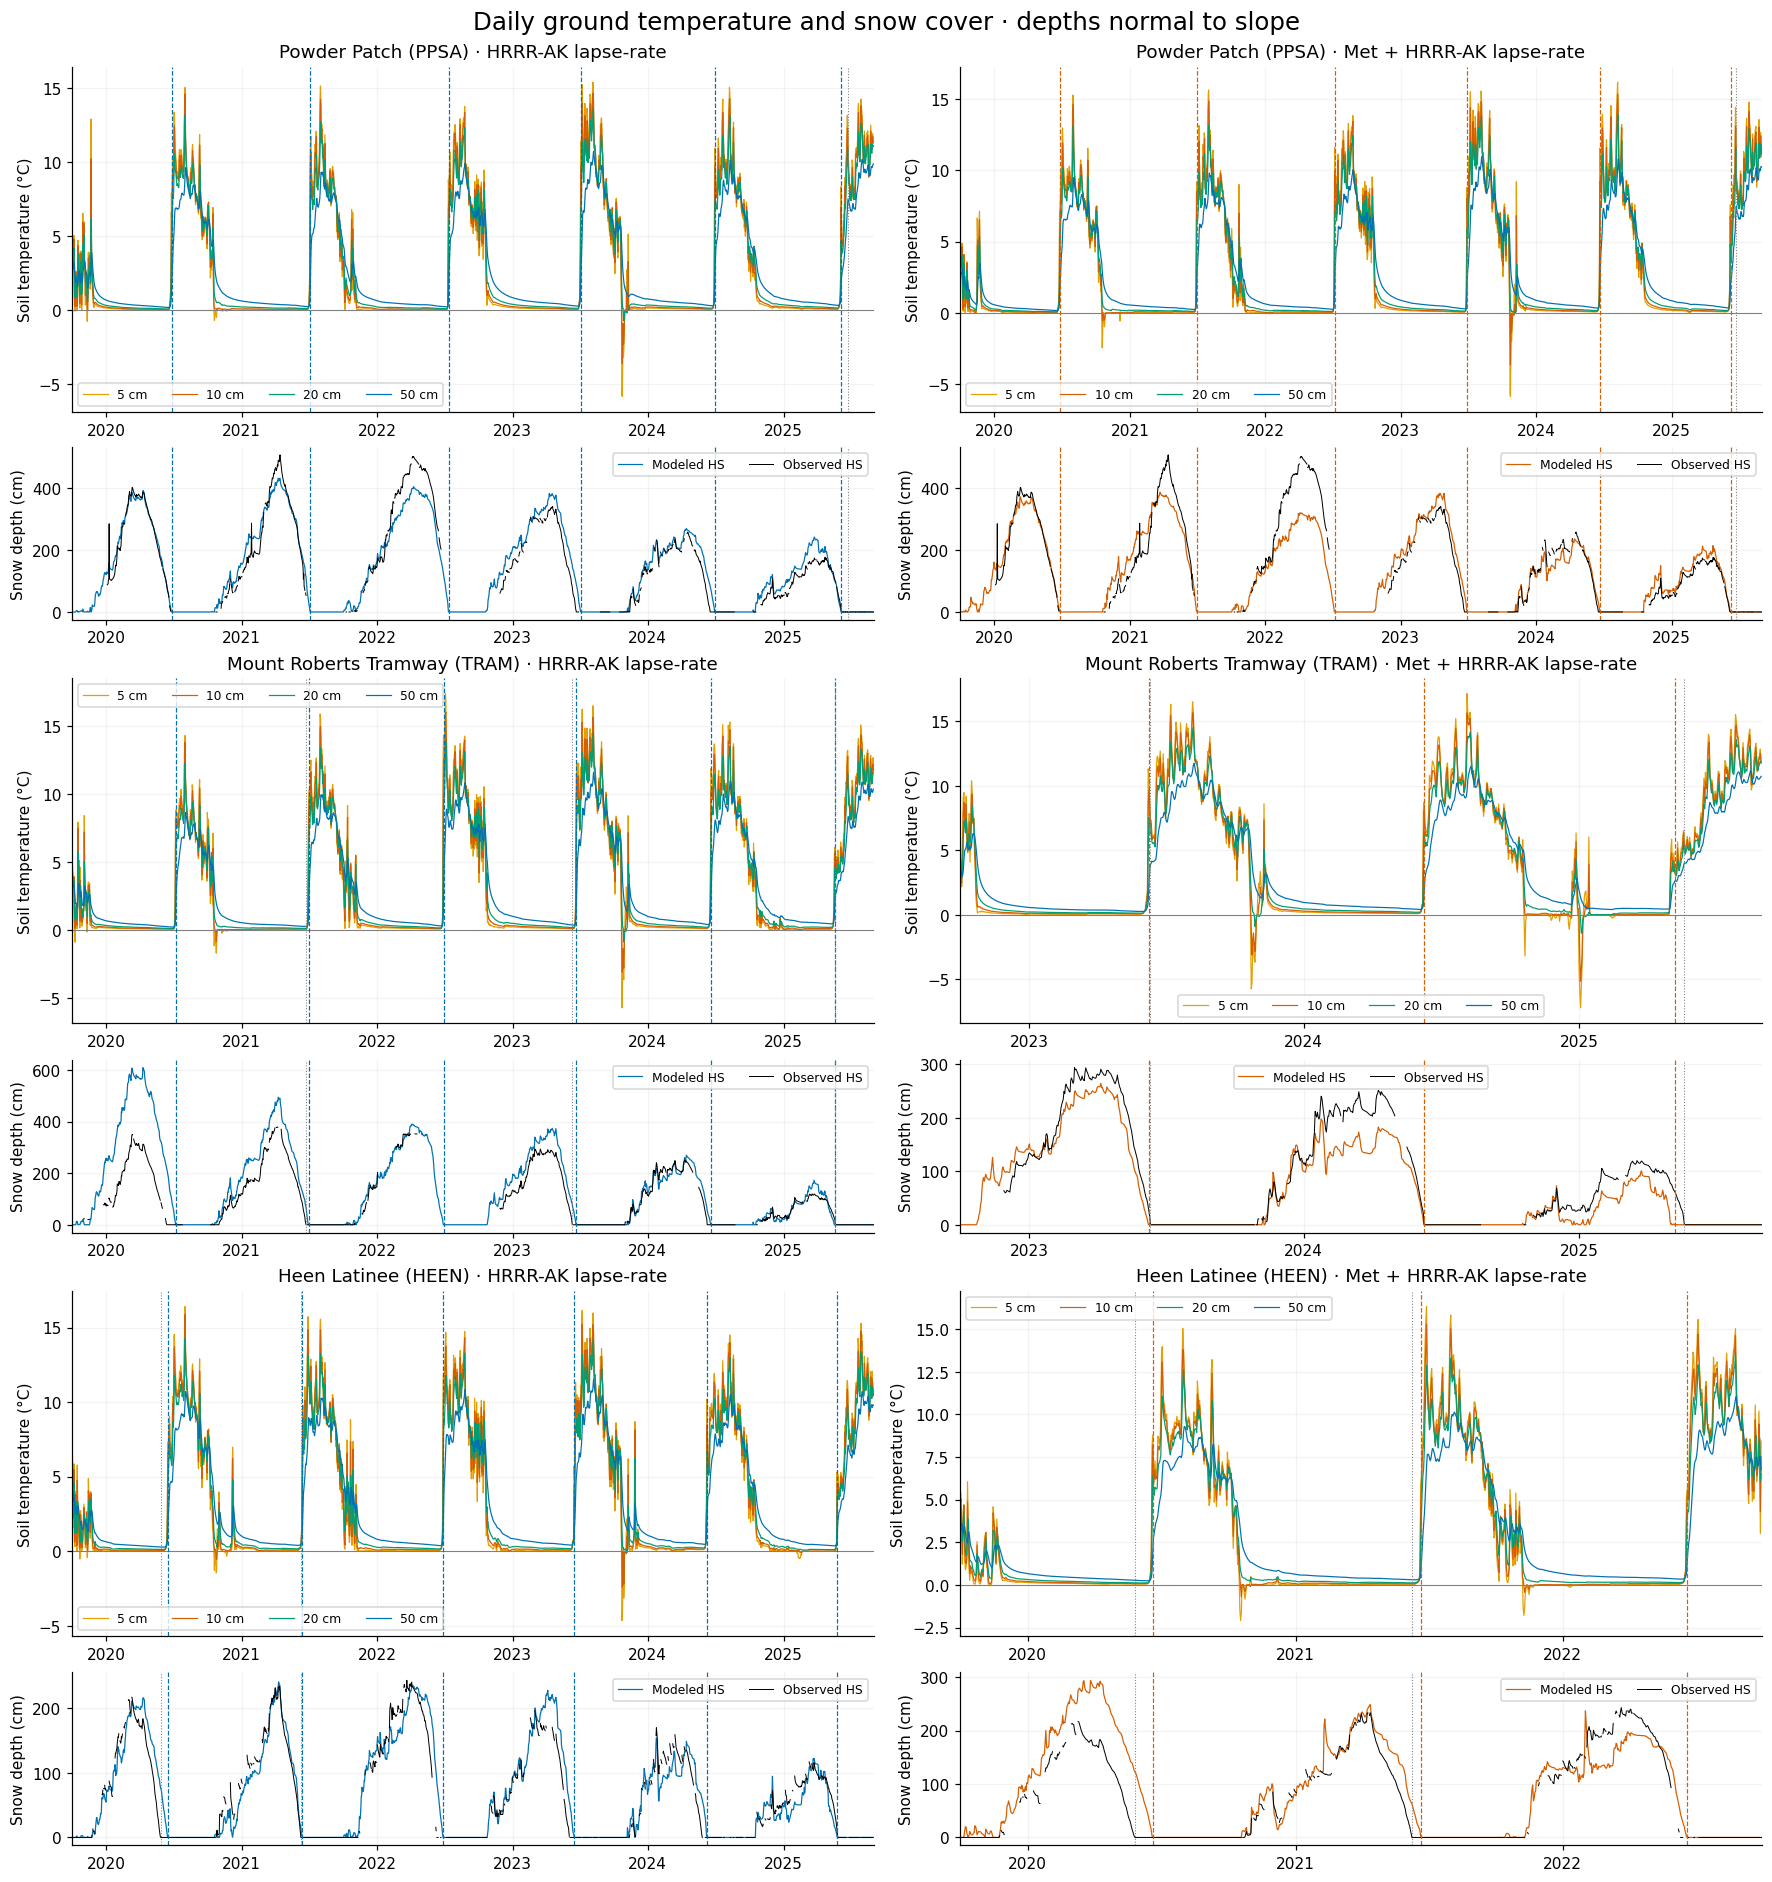

In [4]:
fig,axs=plt.subplots(6,2,figsize=(16,17),layout='constrained',gridspec_kw={'height_ratios':[2,1]*3})
colors=['#E69F00','#D55E00','#009E73','#0072B2']
for r,(site,cfg) in enumerate(SITE_CONFIG.items()):
    for c,forcing in enumerate(FORCINGS):
        d=daily[site,forcing];a,b=axs[2*r,c],axs[2*r+1,c]
        for z,col in zip(DEPTHS,colors):a.plot(d.index,d[f'T_{z}'],color=col,lw=.8,label=f'{z} cm')
        a.axhline(0,color='gray',lw=.7);a.set(title=f'{cfg["title"]} · {LABELS[forcing]}',ylabel='Soil temperature (°C)')
        b.plot(d.index,d.HS_cm,color=COLORS[forcing],lw=.8,label='Modeled HS')
        o=obs[site].resample('D').mean().where(obs[site].resample('D').count()>=18).reindex(d.index)
        b.plot(o.index,o,color='black',lw=.65,label='Observed HS');b.set(ylabel='Snow depth (cm)')
        m=metrics.query('site==@site and forcing==@forcing and depth_cm==5')
        for ax in [a,b]:
            for date in m.melt_date.dropna():ax.axvline(date,color=COLORS[forcing],ls='--',lw=.8)
            for date in m.observed_melt.dropna():ax.axvline(date,color='gray',ls=':',lw=.7)
            ax.set_xlim(d.index.min(),d.index.max());ax.grid(alpha=.15)
            ax.xaxis.set_major_locator(mdates.YearLocator());ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        a.legend(ncol=4,fontsize=8);b.legend(ncol=2,fontsize=8)
fig.suptitle('Daily ground temperature and snow cover · depths normal to slope',fontsize=16)
save(fig,'seasonal_overview');plt.show()


## A complete representative spring at each site
Selection rule: latest common water year with confirmed melt in both forcings and **all 91 daily means valid** at all plotted depths over each forcing's −45…+45 day interval, with both intervals entirely in the record. Same water year within a site; sites may differ. Both panels share a calendar-date range spanning the two intervals. Each melt date is marked separately; a 0°C contour is drawn only where the profile crosses zero. White cells preserve missing data. A shared color scale permits comparison.


,selected_water_year
ppsa,2025
tram,2025
heen,2022


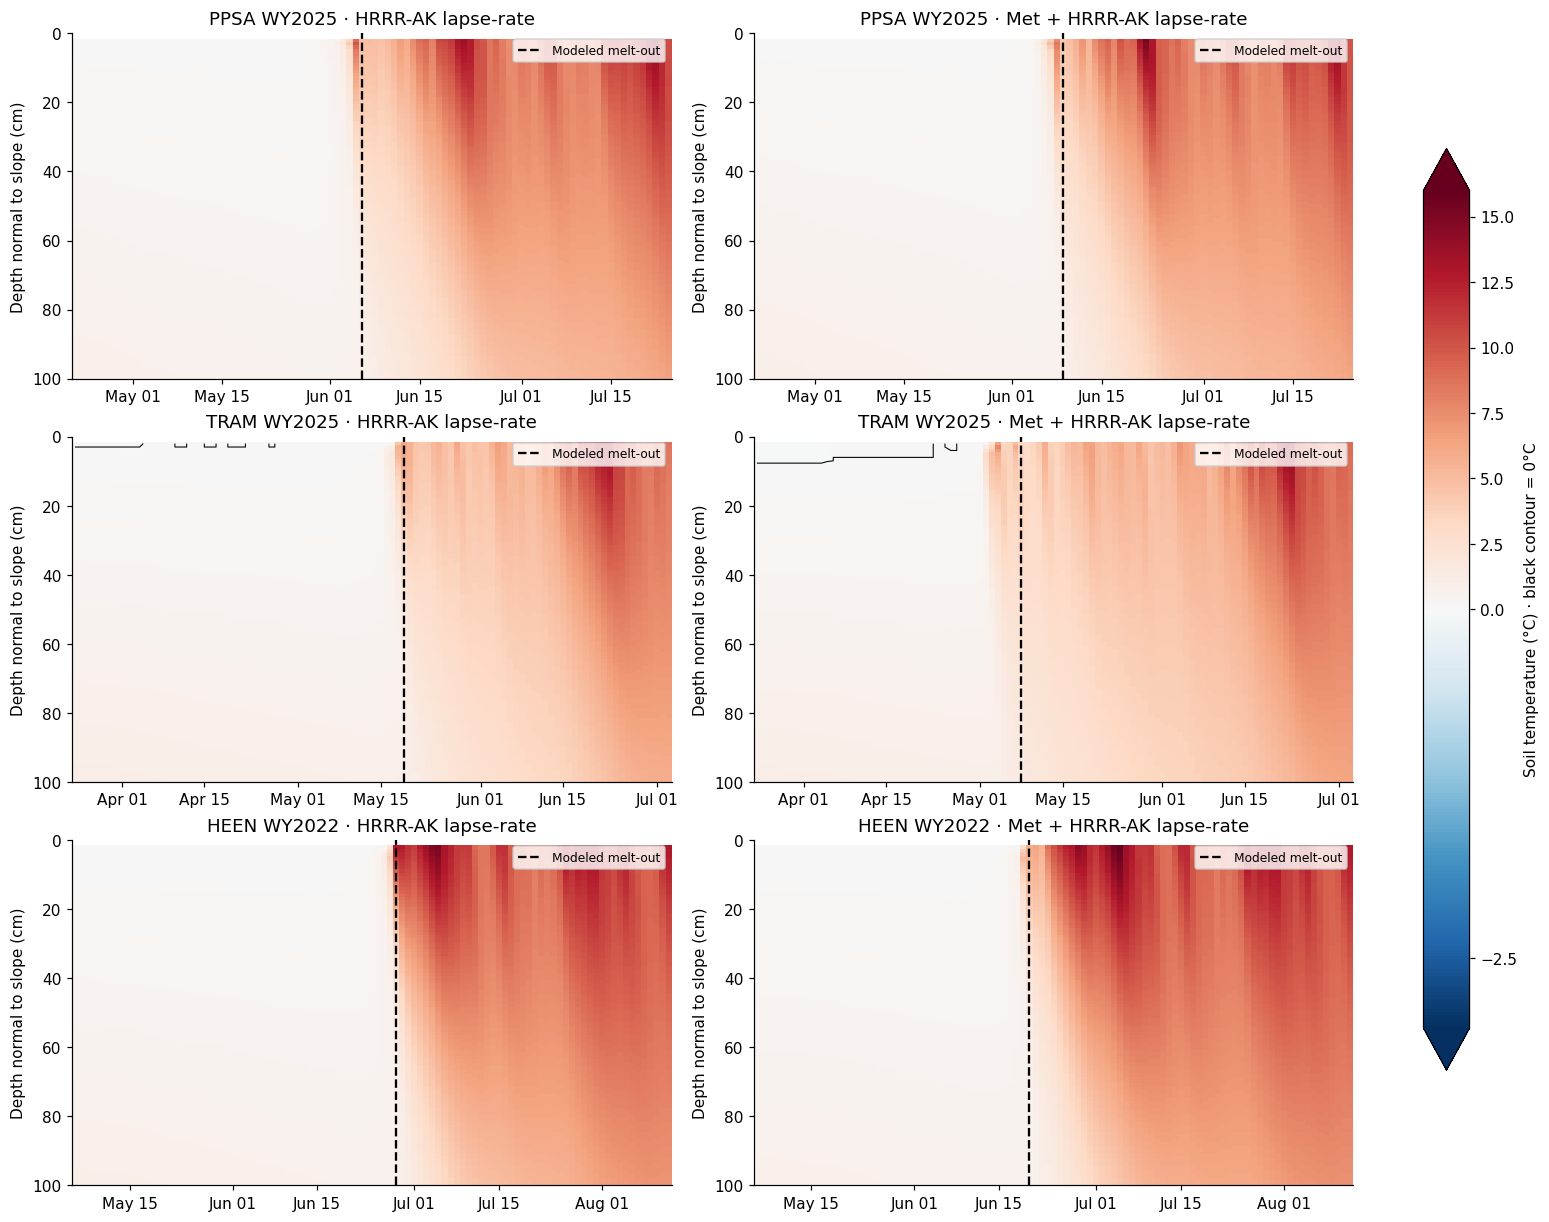

In [5]:
selected={};heat_daily={}
for key,p in profiles.items():
    a=p['T'].iloc[:,4:];heat_daily[key]=a.resample('D').mean().where(a.resample('D').count()>=18)
for site in SITE_CONFIG:
    candidates=[]
    for wy in sorted(metrics.loc[metrics.site==site,'water_year'].unique(),reverse=True):
        ok=True
        for f in FORCINGS:
            m=metrics.query('site==@site and forcing==@f and water_year==@wy and depth_cm==5')
            if len(m)!=1 or pd.isna(m.iloc[0].melt_date):ok=False;break
            melt=m.iloc[0].melt_date;idx=pd.date_range(melt-pd.Timedelta(days=45),melt+pd.Timedelta(days=45))
            if not heat_daily[site,f].reindex(idx).notna().all().all():ok=False
        if ok:selected[site]=int(wy);break
    assert site in selected, f'No complete common spring: {site}'
depth_response=[]
for site,wy in selected.items():
    for f in FORCINGS:
        melt=metrics.query('site==@site and forcing==@f and water_year==@wy and depth_cm==5').iloc[0].melt_date
        for depth in [5,10,20,50,100]:
            series=heat_daily[site,f].iloc[:,int(depth)-2]
            pre,_=window(series,pd.date_range(melt-pd.Timedelta(days=14),periods=14),14)
            post,_=window(series,pd.date_range(melt+pd.Timedelta(days=1),periods=14),14)
            depth_response.append(dict(site=site,forcing=f,water_year=wy,depth_cm=depth,pre14_C=pre,post14_C=post,change_C=post-pre))
depth_response=pd.DataFrame(depth_response);export(depth_response,'representative_depth_response')
display(pd.Series(selected,name='selected_water_year').to_frame())
export(pd.DataFrame([dict(site=s,water_year=y) for s,y in selected.items()]),'selected_springs')
fig,axs=plt.subplots(3,2,figsize=(14,11),layout='constrained')
for r,site in enumerate(SITE_CONFIG):
    year=selected[site];mr=metrics.query('site==@site and water_year==@year and depth_cm==5')
    left=mr.melt_date.min()-pd.Timedelta(days=45);right=mr.melt_date.max()+pd.Timedelta(days=45)
    for c,f in enumerate(FORCINGS):
        ax=axs[r,c];a=heat_daily[site,f].reindex(pd.date_range(left,right));x=mdates.date2num(a.index)
        im=ax.pcolormesh(x,GRID,a.T,cmap='RdBu_r',norm=TwoSlopeNorm(vmin=-3,vcenter=0,vmax=16),shading='auto',rasterized=True)
        if np.nanmin(a.values)<0<np.nanmax(a.values):ax.contour(x,GRID,a.T,levels=[0],colors='black',linewidths=.7)
        melt=mr.loc[mr.forcing==f,'melt_date'].iloc[0];ax.axvline(melt,color='black',ls='--',label='Modeled melt-out')
        ax.set(title=f'{site.upper()} WY{year} · {LABELS[f]}',ylabel='Depth normal to slope (cm)',ylim=(100,0))
        ax.xaxis_date();ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'));ax.legend(fontsize=8)
fig.colorbar(im,ax=axs,label='Soil temperature (°C) · black contour = 0°C',shrink=.8,extend='both')
save(fig,'spring_temperature_depth');plt.show()


## Water, ice and energy timing
All water and ice curves below are **local volume fractions at the same reconstructed 5 and 20 cm depths**, not column mass. `MS_Water_Soil` and `MS_Ice_Soil` are separate integrated kg m⁻² diagnostics. Snow-base outflow (`MS_SN_Runoff`) is a virtual lysimeter rate in kg m⁻² h⁻¹; daily mean rate is shown, not cumulative drainage. `Qg0` is positive upward; the plotted negative sign expresses downward soil heating. Prescribed `Qg=0.06 W m⁻²` is distinguished from this changing surface exchange. Coincidence of water, ice, temperature and flux changes supports interpretation but does not isolate conduction, infiltration heat, radiation and latent heat contributions.


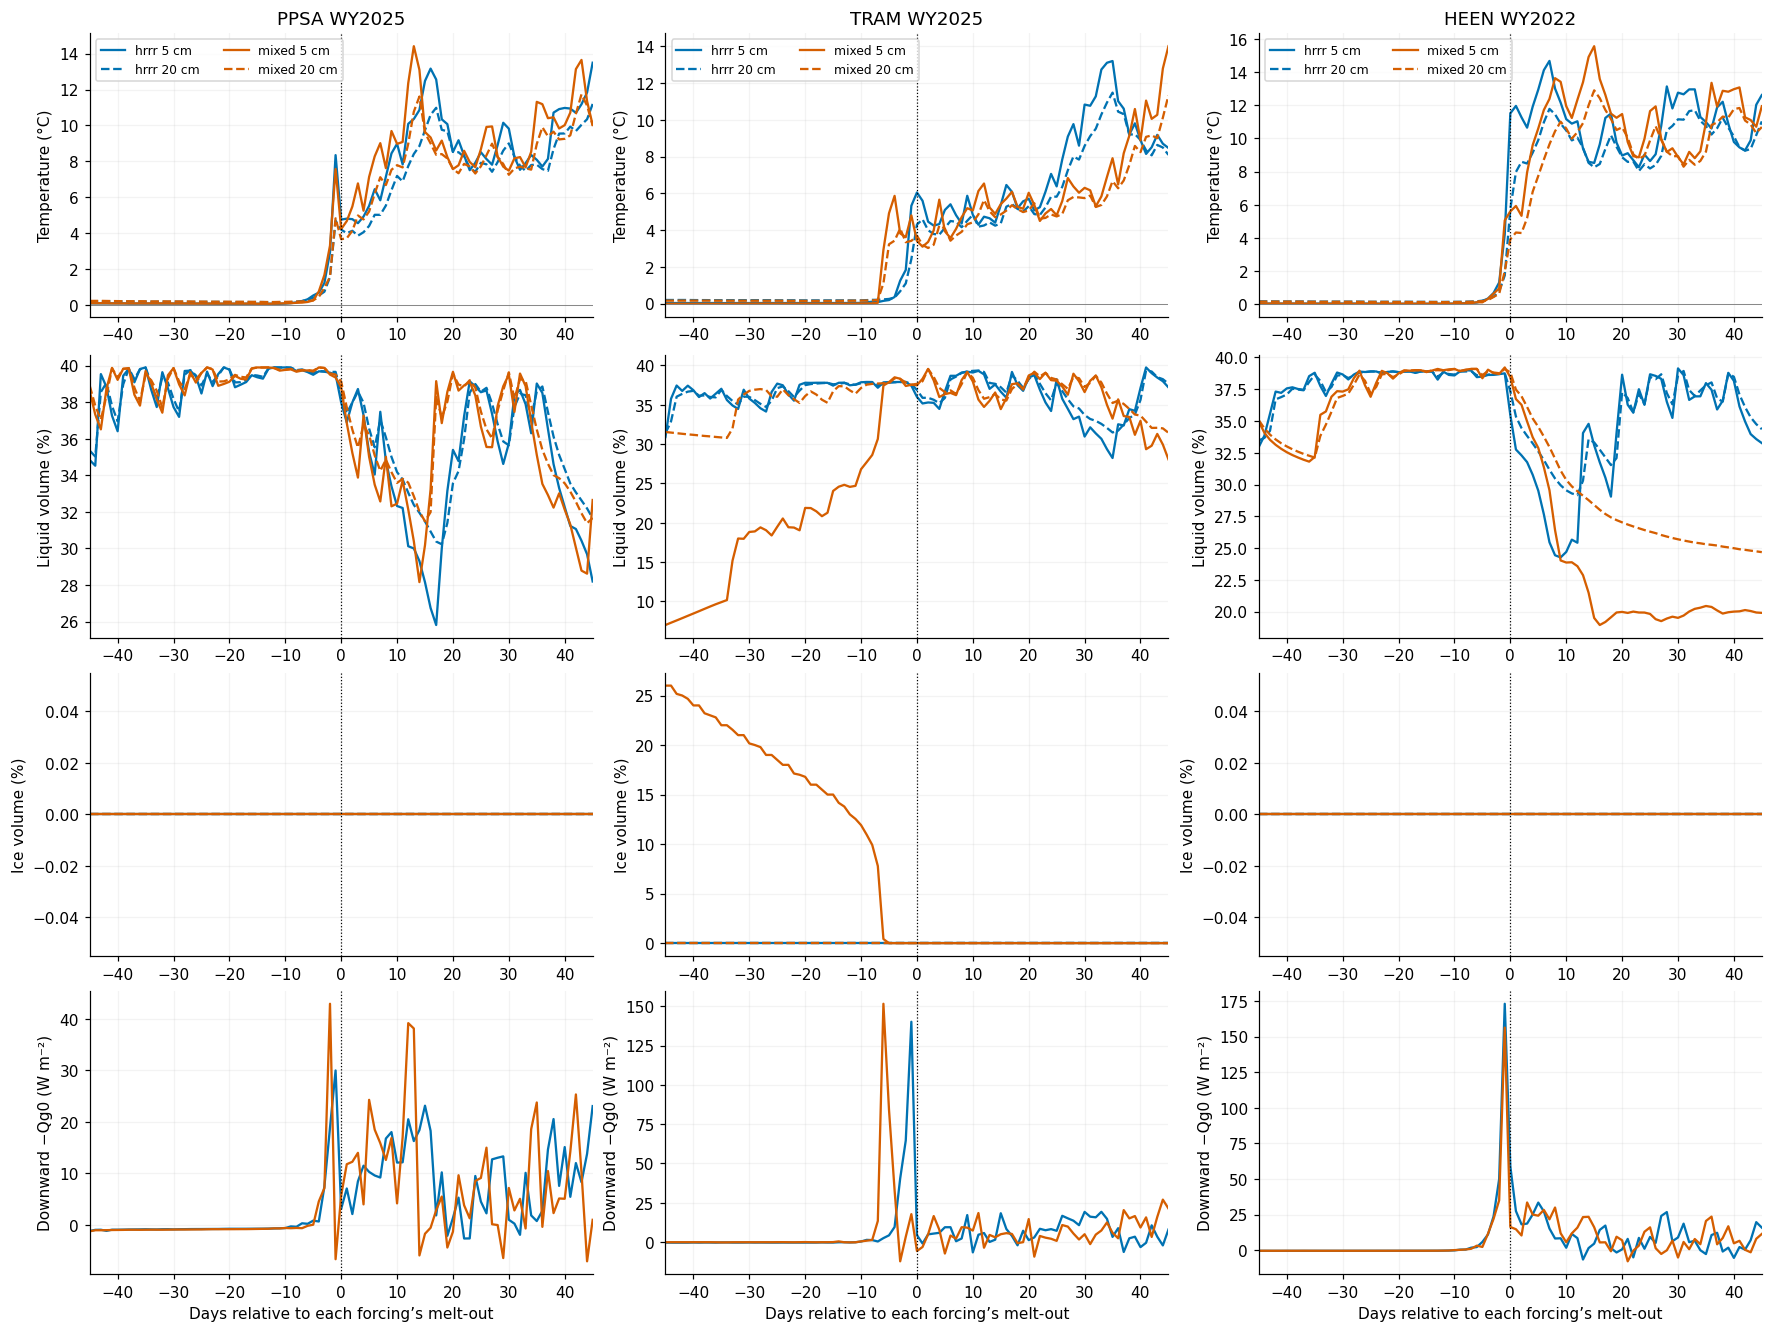

,site,forcing,water_year,near_zero_days,near_zero_ice_max_pct,near_zero_ice_min_pct,ice_at_minus14_pct,ice_at_plus14_pct,water_at_minus14_pct,water_at_plus14_pct,downward_Qg0_pre14_Wm2,downward_Qg0_post14_Wm2
0,ppsa,hrrr,2025,39,0.0,0.000,0.000,0.0,39.288,29.313,3.873,12.306
1,ppsa,mixed,2025,40,0.0,0.000,0.000,0.0,39.896,28.158,3.033,15.895
2,tram,hrrr,2025,41,0.0,0.000,0.000,0.0,37.796,37.583,18.886,4.256
3,tram,mixed,2025,39,26.0,7.791,14.166,0.0,24.584,36.562,20.983,5.267
4,heen,hrrr,2022,41,0.0,0.000,0.000,0.0,38.900,34.779,19.105,14.201
5,heen,mixed,2022,41,0.0,0.000,0.000,0.0,38.971,21.488,16.530,19.995


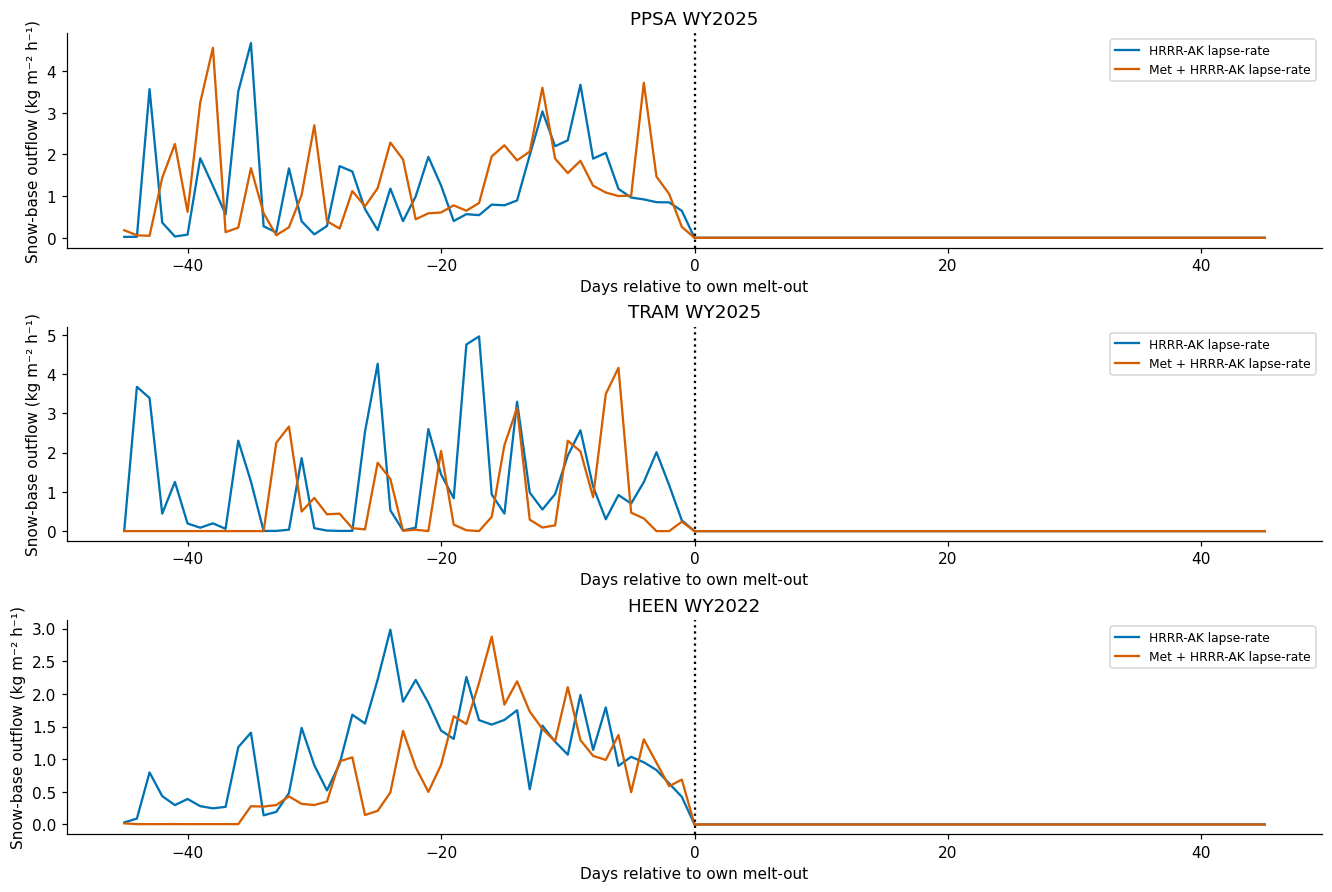

In [6]:
fig,axs=plt.subplots(4,3,figsize=(16,12),layout='constrained');physical=[]
for c,site in enumerate(SITE_CONFIG):
    wy=selected[site]
    for f in FORCINGS:
        m=metrics.query('site==@site and forcing==@f and water_year==@wy and depth_cm==5').iloc[0];melt=m.melt_date
        a=daily[site,f].reindex(pd.date_range(melt-pd.Timedelta(days=45),melt+pd.Timedelta(days=45)));relative=(a.index-melt).days
        for z,ls in [(5,'-'),(20,'--')]:
            for row,var in [(0,'T'),(1,'water'),(2,'ice')]:axs[row,c].plot(relative,a[f'{var}_{z}'],color=COLORS[f],ls=ls,label=f'{f} {z} cm')
        axs[3,c].plot(relative,-a.Qg0,color=COLORS[f],label=f'{f}: −Qg0')
        near=a.loc[a.T_5.abs()<=.25]
        physical.append(dict(site=site,forcing=f,water_year=wy,near_zero_days=len(near),near_zero_ice_max_pct=near.ice_5.max(),near_zero_ice_min_pct=near.ice_5.min(),
            ice_at_minus14_pct=a.ice_5.iloc[31],ice_at_plus14_pct=a.ice_5.iloc[59],water_at_minus14_pct=a.water_5.iloc[31],water_at_plus14_pct=a.water_5.iloc[59],
            downward_Qg0_pre14_Wm2=a.Qg0.iloc[31:45].mul(-1).mean(),downward_Qg0_post14_Wm2=a.Qg0.iloc[46:60].mul(-1).mean()))
    for row,label in enumerate(['Temperature (°C)','Liquid volume (%)','Ice volume (%)','Downward −Qg0 (W m⁻²)']):
        ax=axs[row,c];ax.axvline(0,color='black',ls=':',lw=.8);ax.set(ylabel=label,xlim=(-45,45));ax.grid(alpha=.15)
        if row==3:ax.set_xlabel('Days relative to each forcing’s melt-out')
    axs[0,c].set_title(f'{site.upper()} WY{wy}');axs[0,c].axhline(0,color='gray',lw=.6);axs[0,c].legend(fontsize=8,ncol=2)
save(fig,'spring_temperature_water_ice_flux');plt.show()
physical=pd.DataFrame(physical);export(physical,'physical_diagnostics');display(physical.round(3))
fig,axs=plt.subplots(3,1,figsize=(12,8),layout='constrained')
for ax,site in zip(axs,SITE_CONFIG):
    wy=selected[site]
    for f in FORCINGS:
        melt=metrics.query('site==@site and forcing==@f and water_year==@wy and depth_cm==5').iloc[0].melt_date
        a=daily[site,f].loc[melt-pd.Timedelta(days=45):melt+pd.Timedelta(days=45)]
        ax.plot((a.index-melt).days,a.MS_SN_Runoff,color=COLORS[f],label=LABELS[f])
    ax.axvline(0,color='black',ls=':');ax.set(title=f'{site.upper()} WY{wy}',ylabel='Snow-base outflow (kg m⁻² h⁻¹)',xlabel='Days relative to own melt-out');ax.legend(fontsize=8)
save(fig,'spring_snow_base_outflow');plt.show()


## Paired forcing differences and exceptions
Mixed minus HRRR is computed only on common water years. The calendar comparison uses **identical dates** in March–August and at least 90% paired daily coverage. The melt-relative comparison averages both runs over offsets −14…+14 on their **own** melt dates, requiring all 29 paired offsets. It is descriptive alignment, not a causal decomposition: atmospheric conditions still differ. Melt-date shifts, first-season flags, and valid-day counts are retained. Seasonal summaries also report winter and pre/post differences on common years.


calendar_mixed_minus_hrrr_C  melt_relative_mixed_minus_hrrr_C  \
site depth_cm                                                                  
heen 5                               -0.49                              0.45   
     10                              -0.49                              0.38   
     20                              -0.49                              0.26   
     50                              -0.49                              0.02   
ppsa 5                                0.26                             -0.19   
     10                               0.25                             -0.15   
     20                               0.24                             -0.10   
     50                               0.21                             -0.03   
tram 5                                0.56                             -0.70   
     10                               0.55                             -0.69   
     20                               0.52                             -0.65   
     50                               0.45                             -0.54   

               melt_shift_days  winter_difference_C  post14_difference_C  
site depth_cm                                                             
heen 5                     4.0                -0.05                 0.86  
     10                    4.0                -0.10                 0.74  
     20                    4.0                -0.11                 0.54  
     50                    4.0                -0.15                 0.11  
ppsa 5                    -5.0                -0.00                -0.18  
     10                   -5.0                -0.01                -0.12  
     20                   -5.0                -0.01                -0.04  
     50                   -5.0                 0.01                -0.00  
tram 5                   -11.0                -0.00                -1.84  
     10                  -11.0                -0.00                -1.76  
     20                  -11.0                -0.01                -1.60  
     50                  -11.0                -0.01                -1.12

,site,forcing,water_year,depth_cm,T_melt_C,post14_C,warming_lag_days,warming_status
0,ppsa,hrrr,2020,5,5.98,10.42,-4.0,observed_crossing
1,ppsa,hrrr,2020,10,5.37,9.81,-4.0,observed_crossing
2,ppsa,hrrr,2020,20,4.40,8.61,-3.0,observed_crossing
3,ppsa,hrrr,2020,50,1.97,5.57,-2.0,observed_crossing
4,ppsa,hrrr,2021,5,11.15,9.44,-3.0,observed_crossing
...,...,...,...,...,...,...,...,...
115,heen,mixed,2021,50,1.38,5.95,-1.0,observed_crossing
116,heen,mixed,2022,5,5.61,11.03,-3.0,observed_crossing
117,heen,mixed,2022,10,5.11,10.23,-3.0,observed_crossing
118,heen,mixed,2022,20,3.93,8.72,-2.0,observed_crossing


/tmp/ipykernel_3646204/3542834869.py:36: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  plateaus=pd.DataFrame(plateaus);export(plateaus,'near_zero_episodes');display(plateaus.round(3))


,site,forcing,water_year,start,end,days,ice_start_pct,ice_end_pct,ice_change_pct,water_start_pct,water_end_pct
0,ppsa,hrrr,2025,2025-04-22,2025-05-30,39,0.0,0.000,0.000,34.838,39.754
1,ppsa,mixed,2025,2025-04-25,2025-06-03,40,0.0,0.000,0.000,38.617,39.738
2,tram,hrrr,2025,2025-04-04,2025-05-14,41,0.0,0.000,0.000,30.900,37.887
3,tram,mixed,2025,2025-03-24,2025-05-01,39,26.0,7.791,-18.208,7.009,30.659
4,heen,hrrr,2022,2022-05-14,2022-06-23,41,0.0,0.000,0.000,32.967,38.500
5,heen,mixed,2022,2022-05-06,2022-06-15,41,0.0,0.000,0.000,34.958,38.367


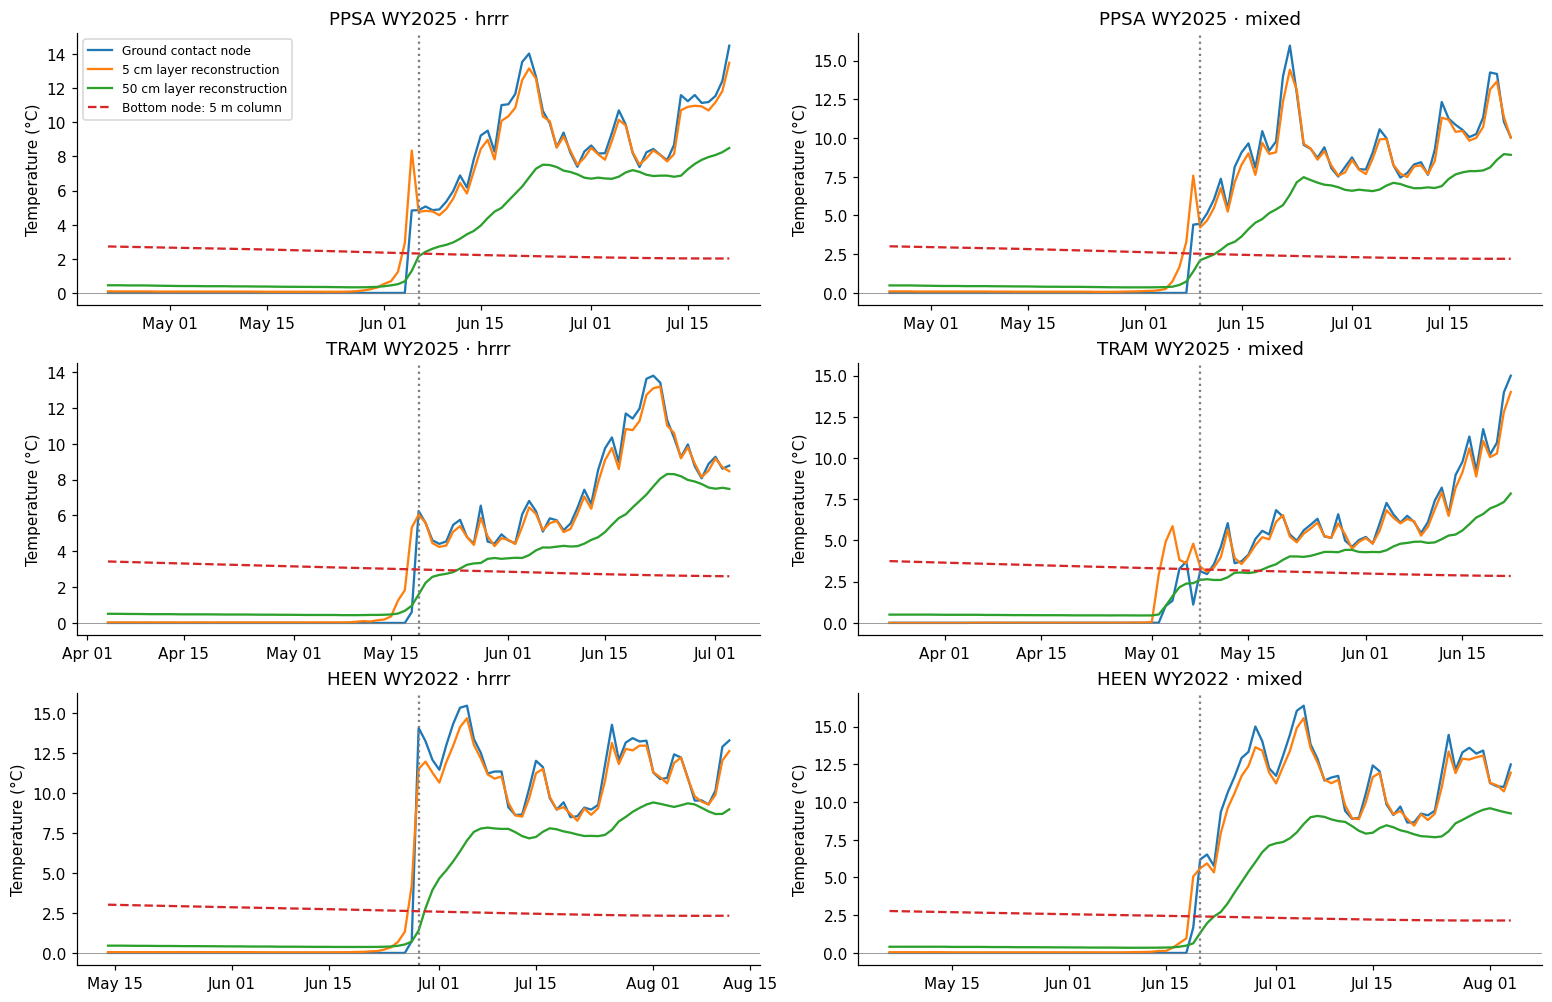

In [7]:
paired=[]
for site in SITE_CONFIG:
    a=metrics.query('site==@site and forcing=="hrrr"');b=metrics.query('site==@site and forcing=="mixed"')
    common=a.merge(b,on=['site','water_year','depth_cm'],suffixes=('_hrrr','_mixed'))
    for _,r in common.iterrows():
        wy=int(r.water_year);z=int(r.depth_cm);idx=pd.date_range(f'{wy}-03-01',f'{wy}-08-31')
        cal=pd.concat([daily[site,'hrrr'][f'T_{z}'].reindex(idx),daily[site,'mixed'][f'T_{z}'].reindex(idx)],axis=1).dropna()
        rel=[]
        if pd.notna(r.melt_date_hrrr) and pd.notna(r.melt_date_mixed):
            for offset in range(-14,15):
                ah=daily[site,'hrrr'][f'T_{z}'].get(r.melt_date_hrrr+pd.Timedelta(days=offset),np.nan)
                bm=daily[site,'mixed'][f'T_{z}'].get(r.melt_date_mixed+pd.Timedelta(days=offset),np.nan);rel.append(bm-ah)
        paired.append(dict(site=site,water_year=wy,depth_cm=z,either_first_season=r.first_simulated_season_hrrr or r.first_simulated_season_mixed,
            common_calendar_days=len(cal),calendar_mixed_minus_hrrr_C=(cal.iloc[:,1]-cal.iloc[:,0]).mean() if len(cal)>=.9*len(idx) else np.nan,
            relative_valid_offsets=int(np.isfinite(rel).sum()),melt_relative_mixed_minus_hrrr_C=np.mean(rel) if len(rel)==29 and np.isfinite(rel).all() else np.nan,
            melt_shift_days=(r.melt_date_mixed-r.melt_date_hrrr).days if pd.notna(r.melt_date_mixed) and pd.notna(r.melt_date_hrrr) else np.nan,
            winter_difference_C=r.winter_mean_C_mixed-r.winter_mean_C_hrrr,post14_difference_C=r.post14_C_mixed-r.post14_C_hrrr,
            melt_temperature_difference_C=r.T_melt_C_mixed-r.T_melt_C_hrrr))
paired=pd.DataFrame(paired);export(paired,'paired_forcing_differences')
display(paired.groupby(['site','depth_cm'])[['calendar_mixed_minus_hrrr_C','melt_relative_mixed_minus_hrrr_C','melt_shift_days','winter_difference_C','post14_difference_C']].median().round(2))
exceptions=metrics.loc[(metrics.warming_lag_days<0)|((metrics.depth_cm==5)&(metrics.post14_C.abs()<=.5))|((metrics.depth_cm>=20)&metrics.warming_status.ne('observed_crossing'))]
export(exceptions,'exceptions');display(exceptions[['site','forcing','water_year','depth_cm','T_melt_C','post14_C','warming_lag_days','warming_status']].round(2))
# Inspect contiguous near-zero episodes, with local ice change in time order.
plateaus=[]
for site in SITE_CONFIG:
    wy=selected[site]
    for f in FORCINGS:
        melt=metrics.query('site==@site and forcing==@f and water_year==@wy and depth_cm==5').iloc[0].melt_date
        a=daily[site,f].reindex(pd.date_range(melt-pd.Timedelta(days=45),melt+pd.Timedelta(days=45)))
        near=a.T_5.abs()<=.25;groups=(near!=near.shift()).cumsum()
        for _,segment in a.loc[near].groupby(groups[near]):
            if len(segment)<3:continue
            plateaus.append(dict(site=site,forcing=f,water_year=wy,start=segment.index[0],end=segment.index[-1],days=len(segment),
                ice_start_pct=segment.ice_5.iloc[0],ice_end_pct=segment.ice_5.iloc[-1],ice_change_pct=segment.ice_5.iloc[-1]-segment.ice_5.iloc[0],
                water_start_pct=segment.water_5.iloc[0],water_end_pct=segment.water_5.iloc[-1]))
plateaus=pd.DataFrame(plateaus);export(plateaus,'near_zero_episodes');display(plateaus.round(3))
# Distinguish surface, buried layers, and bottom-node thermal history.
fig,axs=plt.subplots(3,2,figsize=(14,9),layout='constrained')
for r,site in enumerate(SITE_CONFIG):
    wy=selected[site]
    for c,f in enumerate(FORCINGS):
        melt=metrics.query('site==@site and forcing==@f and water_year==@wy and depth_cm==5').iloc[0].melt_date
        a=daily[site,f].loc[melt-pd.Timedelta(days=45):melt+pd.Timedelta(days=45)]
        ax=axs[r,c]
        for field,label,style in [('TSG','Ground contact node','-'),('T_5','5 cm layer reconstruction','-'),('T_50','50 cm layer reconstruction','-'),('T_bottom','Bottom node: 5 m column','--')]:
            ax.plot(a.index,a[field],ls=style,label=label)
        ax.axvline(melt,color='gray',ls=':');ax.axhline(0,color='gray',lw=.5)
        ax.set(title=f'{site.upper()} WY{wy} · {f}',ylabel='Temperature (°C)');ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axs[0,0].legend(fontsize=8);save(fig,'surface_layers_bottom');plt.show()
# Output daily extracted temperatures and matching diagnostics for reuse.
for (site,f),d in daily.items():
    cols=[f'{v}_{z}' for v in ['T','water','ice'] for z in DEPTHS]+['TSG','T_bottom','HS_cm','HS_max_cm','SWE','Qg','Qg0','MS_SN_Runoff','MS_Water_Soil','MS_Ice_Soil']
    d[cols].to_csv(OUT/f'daily_{site}_{f}.csv',index_label='date_UTC')


## What the diagnostics can establish
In the selected PPSA WY2025 and HEEN WY2022 springs, the 5 cm near-zero episodes contain no modeled ice. Their plateaus therefore support a snow-controlled thermal boundary, not local soil-ice melt. In TRAM's mixed-forcing WY2025 run the 39-day near-zero episode has ice declining from approximately 26.0% to 7.8% by volume while liquid water increases; ice subsequently reaches zero before the sharp warming. This supports a local latent-heat contribution in that run. The HRRR-only TRAM profile has no ice in the selected episode, demonstrating forcing-dependent phase behavior under the same assumed material profile.

All retained 5 cm seasons cross the warming threshold before final operational disappearance, with daily mean snow depth still about 6–26 cm on the crossing day. None has a 14-day post-melt mean within ±0.5°C. The longer-lived warmth at 50 cm is a contrasting deeper response; many seasons are already above the warming threshold on March 1. A crossing-based lag cannot describe those seasons.

Snow insulation reduces atmospheric coupling; after disappearance the shallow ground can respond quickly, while conduction and heat storage delay the deeper response. Snow-covered ground can exceed +0.5°C before operational melt-out, especially where deep heat storage or wet snow maintains positive temperatures. A near-zero plateau alone is insufficient to diagnose thaw: compare local ice loss, not only liquid water or integrated storage. Where ice is absent or does not decline, a snow-controlled boundary near freezing and delayed conduction remain plausible explanations. Wetting and snow-base outflow indicate water arrival but do not quantify advected energy.

The initialized 5 m column, loam retention properties, water redistribution, conductivity, slope and prescribed upward geothermal flux all condition the modeled response. These runs cannot isolate soil-profile uncertainty from forcing uncertainty. TRAM's mixed forcing starts later, so its paired differences also include unequal thermal history. No matched soil-temperature observations were identified in the three referenced station datasets or local field-data repository (snow surveys); the exported observation audit lists the inspected station variables. This is a scoped search, not proof that no measurements exist elsewhere. Snow-depth observations validate snow timing only.

## Meeting table and five answers
Medians below exclude each run's first simulated water year and require complete 14-day windows. “Following-two-week warming” means post-melt days 1–14 mean minus temperature on melt day; the pre/post difference is also given. 50 cm lags require observed threshold crossings at both depths. Counts are per quantity, since censored crossings must not silently reduce the temperature sample.


In [8]:
usable=metrics.loc[~metrics.first_simulated_season & ~metrics.incomplete_14d_window]
summary=[]
for (site,f),a in usable.query('depth_cm==5').groupby(['site','forcing'],sort=False):
    deep=usable.query('site==@site and forcing==@f and depth_cm==50')
    summary.append(dict(site=site,forcing=f,temperature_seasons=a.T_melt_C.notna().sum(),typical_5cm_at_melt_C=a.T_melt_C.median(),
        warming_following_2wk_C=a.post_minus_melt_C.median(),post_minus_pre14_C=a.post_minus_pre_C.median(),
        lag50_vs5_days=deep.warming_lag_vs_5cm_days.median(),lag50_vs5_seasons=deep.warming_lag_vs_5cm_days.notna().sum(),
        lag50_vs_melt_days=deep.warming_lag_days.median(),lag50_vs_melt_seasons=deep.warming_lag_days.notna().sum(),already_warm50_seasons=deep.warming_status.eq('already_above_at_start').sum()))
summary=pd.DataFrame(summary);export(summary,'meeting_summary')
checks=[]
for site in SITE_CONFIG:
    shallow=usable.query('site==@site and depth_cm==5')
    deep50=usable.query('site==@site and depth_cm==50')
    checks.append(dict(site=site,shallow_seasons=len(shallow),warming_before_melt=int((shallow.warming_lag_days<0).sum()),
        snow_HS_at_crossing_min_cm=shallow.warming_HS_mean_cm.min(),snow_HS_at_crossing_max_cm=shallow.warming_HS_mean_cm.max(),
        shallow_post14_near_zero=int((shallow.post14_C.abs()<=.5).sum()),deep_seasons=len(deep50),deep_already_warm_March1=int(deep50.warming_status.eq('already_above_at_start').sum())))
checks=pd.DataFrame(checks);export(checks,'exception_summary');display(checks.round(2))
if len(plateaus):
    diminishing=int((plateaus.ice_change_pct<-.1).sum())
    display(Markdown(f'**Phase-change check:** {len(plateaus)} contiguous near-zero episodes (≥3 days) in the selected springs; {diminishing} show a net local ice decline >0.1 percentage point. Inspect each episode’s initial/end ice before attributing the plateau to melting.'))
display(Markdown('**Exception check:** the table above distinguishes warming before final operational melt from snow-free warming, using modeled mean HS on the crossing day. No shallow post-melt near-zero case should be claimed unless its count is nonzero. Deep temperatures often retain enough heat to exceed the threshold at the start of March; this censors the lag without implying absence of later warming.'))
meeting=summary[['site','forcing','temperature_seasons','typical_5cm_at_melt_C','warming_following_2wk_C','lag50_vs5_days','lag50_vs5_seasons']].round(2)
meeting.columns=['Site','Forcing','Temperature n','5 cm at melt (°C)','Post14 minus melt (°C)','50 vs 5 cm lag (days)','Lag n']
display(meeting)
w=usable.query('depth_cm==5').groupby('site').winter_mean_C.median()
lag=usable.query('depth_cm==5').warming_lag_days.dropna();deep=usable.query('depth_cm==50').warming_lag_vs_5cm_days.dropna()
pair5=paired.query('depth_cm==5 and not either_first_season')
metre=depth_response.query('depth_cm==100').change_C
phys_text=[]
for _,r in physical.iterrows():
    phys_text.append(f"{r.site.upper()} {r.forcing}: {r.near_zero_days} near-zero days, local 5 cm ice {r.near_zero_ice_min_pct:.1f}–{r.near_zero_ice_max_pct:.1f}%")
answers=[
    'Under snow: median December–February 5 cm temperatures by site are '+', '.join(f'{s.upper()} {v:.2f}°C' for s,v in w.items())+'. These summarize modeled idealized soil; winter may include snow-free spells.',
    f'Warming begins at the first confirmed >+0.5°C three-day crossing: observed 5 cm lags span {lag.min():.0f} to {lag.max():.0f} days relative to melt-out ({len(lag)} eligible seasons). Negative lags mean warming under remaining snow; censored seasons are retained in the full table.',
    f'Warming penetrates to 50 cm, with observed threshold delays relative to 5 cm of {deep.min():.0f}–{deep.max():.0f} days (median {deep.median():.0f}; n={len(deep)}). Many other 50 cm seasons are already warm on March 1 (counts in table), so this small crossing subset is not representative of every year; selected-spring 1 m pre/post-melt increases span {metre.min():.1f}–{metre.max():.1f}°C. This is not thaw depth.',
    f'Forcing sensitivity: common-year 5 cm calendar differences (mixed minus HRRR) range {pair5.calendar_mixed_minus_hrrr_C.min():.2f}–{pair5.calendar_mixed_minus_hrrr_C.max():.2f}°C; melt-aligned differences range {pair5.melt_relative_mixed_minus_hrrr_C.min():.2f}–{pair5.melt_relative_mixed_minus_hrrr_C.max():.2f}°C. Identical initial layer states do not remove unequal-history effects at TRAM; first years are excluded here.',
    'Defensible conclusions: the idealized runs show insulation and depth-dependent seasonal warming; they cannot establish actual site temperatures, thaw depth or the correct soil profile. Near-zero periods require local ice evidence to attribute latent-heat effects (episode table above).'
]
display(Markdown('\n'.join('- '+s for s in answers)))
(OUT/'meeting_takeaways.md').write_text('# Modeled ground-temperature meeting findings\n\n'+('| '+' | '.join(meeting.columns)+' |\n| '+' | '.join(['---']*len(meeting.columns))+' |\n'+'\n'.join('| '+' | '.join(map(str,row))+' |' for row in meeting.itertuples(index=False,name=None)))+'\n\n'+'\n'.join('- '+s for s in answers)+'\n')
print('Notebook completed. Figures, audit tables and metrics:',OUT)


,site,shallow_seasons,warming_before_melt,snow_HS_at_crossing_min_cm,snow_HS_at_crossing_max_cm,shallow_post14_near_zero,deep_seasons,deep_already_warm_March1
0,ppsa,10,10,9.60,26.32,0,10,6
1,tram,7,7,6.67,22.72,0,7,6
2,heen,7,7,5.63,23.69,0,7,4


**Phase-change check:** 6 contiguous near-zero episodes (≥3 days) in the selected springs; 1 show a net local ice decline >0.1 percentage point. Inspect each episode’s initial/end ice before attributing the plateau to melting.

**Exception check:** the table above distinguishes warming before final operational melt from snow-free warming, using modeled mean HS on the crossing day. No shallow post-melt near-zero case should be claimed unless its count is nonzero. Deep temperatures often retain enough heat to exceed the threshold at the start of March; this censors the lag without implying absence of later warming.

,Site,Forcing,Temperature n,5 cm at melt (°C),Post14 minus melt (°C),50 vs 5 cm lag (days),Lag n
0,ppsa,hrrr,5,10.95,0.57,1.0,2
1,ppsa,mixed,5,9.20,0.20,1.5,2
2,tram,hrrr,5,11.47,-0.99,2.0,1
3,tram,mixed,2,6.08,0.94,NaN,0
4,heen,hrrr,5,7.52,0.19,1.0,1
5,heen,mixed,2,5.99,5.34,1.5,2


- Under snow: median December–February 5 cm temperatures by site are HEEN 0.04°C, PPSA 0.14°C, TRAM 0.16°C. These summarize modeled idealized soil; winter may include snow-free spells.
- Warming begins at the first confirmed >+0.5°C three-day crossing: observed 5 cm lags span -6 to -2 days relative to melt-out (24 eligible seasons). Negative lags mean warming under remaining snow; censored seasons are retained in the full table.
- Warming penetrates to 50 cm, with observed threshold delays relative to 5 cm of 1–2 days (median 1; n=8). Many other 50 cm seasons are already warm on March 1 (counts in table), so this small crossing subset is not representative of every year; selected-spring 1 m pre/post-melt increases span 1.1–2.3°C. This is not thaw depth.
- Forcing sensitivity: common-year 5 cm calendar differences (mixed minus HRRR) range -0.49–0.59°C; melt-aligned differences range -1.06–0.87°C. Identical initial layer states do not remove unequal-history effects at TRAM; first years are excluded here.
- Defensible conclusions: the idealized runs show insulation and depth-dependent seasonal warming; they cannot establish actual site temperatures, thaw depth or the correct soil profile. Near-zero periods require local ice evidence to attribute latent-heat effects (episode table above).

Notebook completed. Figures, audit tables and metrics: /home/cassie/python/repos/snow_modeling_point/figures/soil_temperature
